# Retrieval-головы Qwen3-8B: задача из статьи

Метрики и графики по прогонам на задаче «игла в стоге сена» из статьи [Retrieval Head Mechanistically Explains Long-Context Factuality](https://arxiv.org/html/2404.15574v1).

Ноутбук читает только готовые результаты `rh.run` / `rh.metrics` (`samples.jsonl`, `heads/*.npz`, `spool/run.json`), модель не нужна.

| Раздел | Прогон | Что показывает | Рисунок статьи |
|---|---|---|---|
| 1 | детекция | качество без маски; распределение голов по скору; скор и частота активации; карта голов | 3, 4, 5 |
| 2 | маскирование | качество от числа отключённых голов по ROUGE-1, ROUGE-2, ROUGE-3 и по критериям на них; карты «длина × глубина»; типы ответов; формулировки ответов (перефразы, замены, формы слов) | 1, 7, 9 |

**Ровные шкалы.** Сетка прогонов не круглая: длины 1000, 2526, 4053, …, глубины 0, 11, 22, … Данные стоят на своих настоящих местах, а деления осей — на круглых значениях (5k, 10k, …; 0, 20, …).

Код графиков — в `vizual/plots.py`, чтение данных — в `vizual/data.py`, цвета и размеры — в `vizual/style.py`.

## 0. Настройки

In [1]:
import os, sys
sys.path.insert(0, os.path.abspath(".."))   # корень репозитория: ноутбук лежит в vizual/

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from vizual import data, paraphrase, plots, style

DETECT = "results/new/qwen3_detect"        # детекция: внимание сохранено, есть скоры голов
MASK = "results/new/qwen3_mask/*"          # перебор масок по рейтингу copy_count

METRIC = "copy_recall"    # скор головы: copy_recall — как в статье (доля скопированных токенов иглы), copy_count — как в коде авторов
THRESHOLD = 0.1           # порог retrieval-головы из статьи
LIMIT = None              # None или 256 — целые ответы (предел прогонов — 256 токенов); 50, 64, 128 — обрезка, для ROUGE-2/3 нужен пересчёт rh.metrics --rescore
SAVE = False              # сохранять рисунки в vizual/figures/

# Внешний вид: всё меняется здесь. Примеры:
#   style.use(scale=1.3, dpi=160)                        крупнее, для слайдов
#   style.use(colors={"top": "#4a3aa7"})                  другой цвет серии
#   style.use(cmap_score="RdYlGn", cmap_heads="viridis")  другая гамма карт (любое имя matplotlib; по умолчанию красная)
#   style.use(font=13)                                     крупнее подписи
style.use(scale=1.0, dpi=110)

def show(ax, name):
    if SAVE:
        plots.save(np.ravel(ax)[0].figure, name)
    plt.show()

## 1. Детекция голов

3 иглы × 20 длин × 10 глубин = 600 примеров, без маски. Скор головы считается по успешным примерам (ROUGE-1 recall > 50), как в статье.

In [2]:
heads = data.Heads(DETECT)
detect = heads.samples
score = heads.score(METRIC)          # [слой, голова]
ranking = heads.ranking(METRIC)
total_heads = score.size

print(f"примеров: {len(detect)}, успешных: {detect['success'].sum()} ({detect['success'].mean():.1%}), средний ROUGE-1 recall: {detect['rouge1_recall'].mean():.1f}")
print(f"ROUGE-2 recall: {detect['rouge2_recall'].mean():.1f}, ROUGE-3 recall: {detect['rouge3_recall'].mean():.1f}; "
      f"успех по ROUGE-2: {detect['success2'].mean():.1%}, по ROUGE-3: {detect['success3'].mean():.1%}, точная фраза: {detect['exact'].mean():.1%}")
print(f"голов: {total_heads} ({len(heads.layers)} слоёв × {heads.n_heads}); метрики голов: {[m for m in heads.metrics if '@' not in m]}")

примеров: 600, успешных: 593 (98.8%), средний ROUGE-1 recall: 98.4
ROUGE-2 recall: 97.1, ROUGE-3 recall: 96.4; успех по ROUGE-2: 98.7%, по ROUGE-3: 98.5%, точная фраза: 90.5%
голов: 1152 (36 слоёв × 32); метрики голов: ['copy_count', 'copy_recall', 'needle_mass']


### 1.1. Качество без маски

Средний ROUGE-1 recall по длине контекста и глубине иглы.

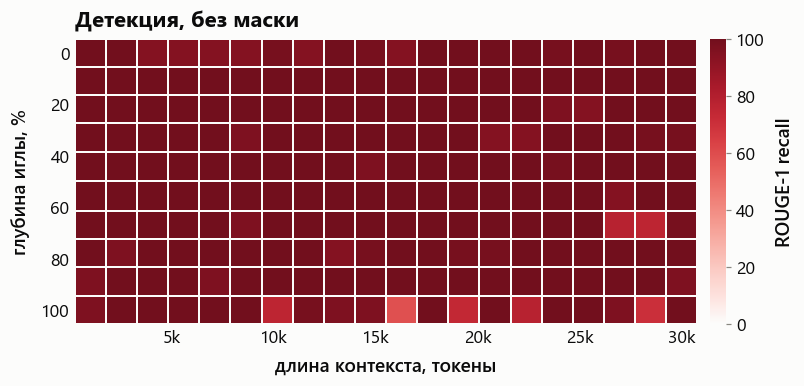

In [3]:
show(plots.niah_heatmap(detect, title="Детекция, без маски"), "detect_niah")

In [4]:
# по иглам: успех и ROUGE
detect.groupby("needle_idx").agg(примеров=("id", "size"), rouge1=("rouge1_recall", "mean"), rouge2=("rouge2_recall", "mean"), rouge3=("rouge3_recall", "mean"),
                                 успех1=("success", "mean"), успех2=("success2", "mean"), успех3=("success3", "mean"), точная_фраза=("exact", "mean"),
                                 токенов=("n_tokens", "mean")).round(3)

,примеров,rouge1,rouge2,rouge3,успех1,успех2,успех3,точная_фраза,токенов
needle_idx,,,,,,,,,
0,200,100.000,100.000,100.000,1.000,1.00,1.000,1.000,36.65
1,200,98.800,98.036,98.000,0.985,0.98,0.980,0.980,31.07
2,200,96.444,93.265,91.062,0.980,0.98,0.975,0.735,42.88


### 1.2. Распределение голов по скору (рис. 3 статьи)

В статье 3–6% голов имеют скор выше 0.1, 45–73% — ровно 0.

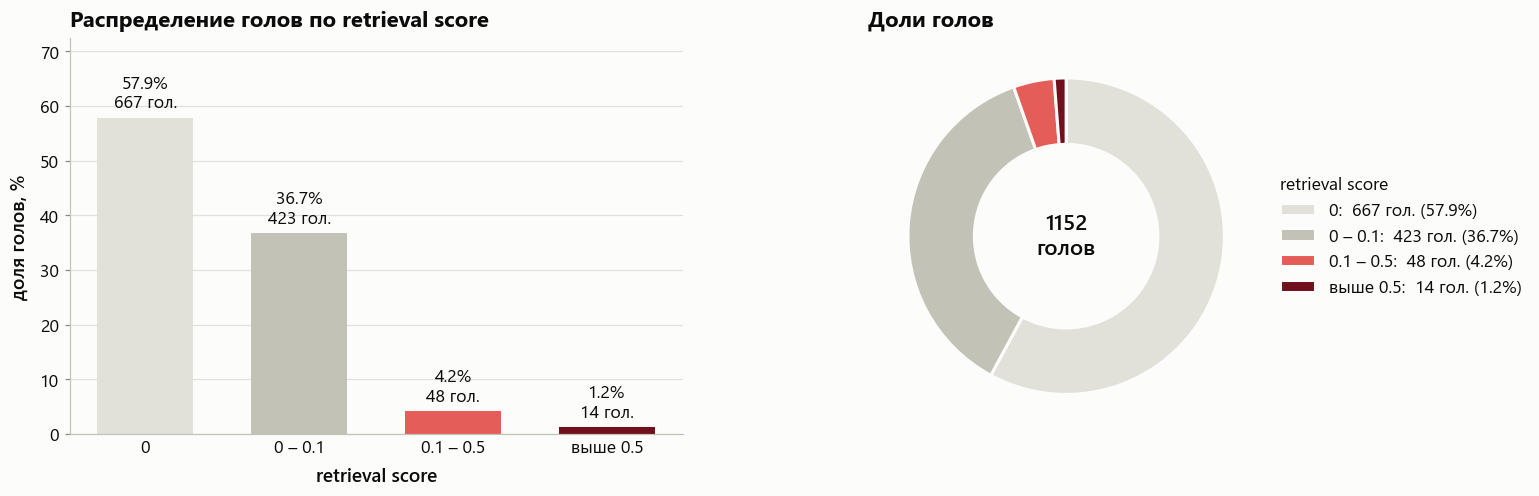

выше порога 0.1: 62 из 1152 голов (5.4%); ровно 0: 57.9%


In [5]:
fig, axes = plt.subplots(1, 2, figsize=style.size(14, 4.4), gridspec_kw={"width_ratios": [1, 1.2]})
plots.score_distribution(score, ax=axes[0], title="Распределение голов по retrieval score")
plots.score_pie(score, ax=axes[1], title="Доли голов")
show(axes, "score_distribution")
above = int((score > THRESHOLD).sum())
print(f"выше порога {THRESHOLD}: {above} из {total_heads} голов ({above / total_heads:.1%}); ровно 0: {(score == 0).mean():.1%}")

### 1.3. Скор и частота активации (рис. 4 статьи)

Частота активации — доля примеров, в которых голова скопировала хотя бы один токен иглы. Головы упорядочены по скору.

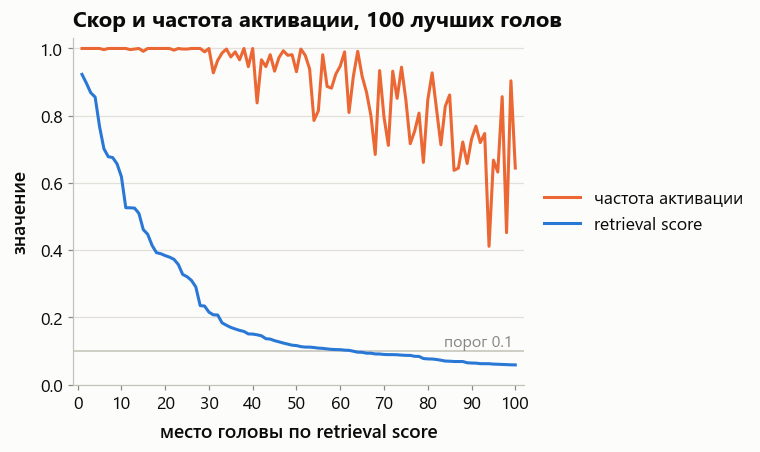

активны во всех успешных примерах: 24 голов; выше порога 0.1: 62


In [6]:
show(plots.score_vs_frequency(ranking, top=100, threshold=THRESHOLD, title="Скор и частота активации, 100 лучших голов"), "score_vs_frequency")
always = int((ranking["frequency"] == 1).sum())
print(f"активны во всех успешных примерах: {always} голов; выше порога {THRESHOLD}: {(ranking['score'] > THRESHOLD).sum()}")

### 1.4. Где находятся головы (рис. 5 статьи)

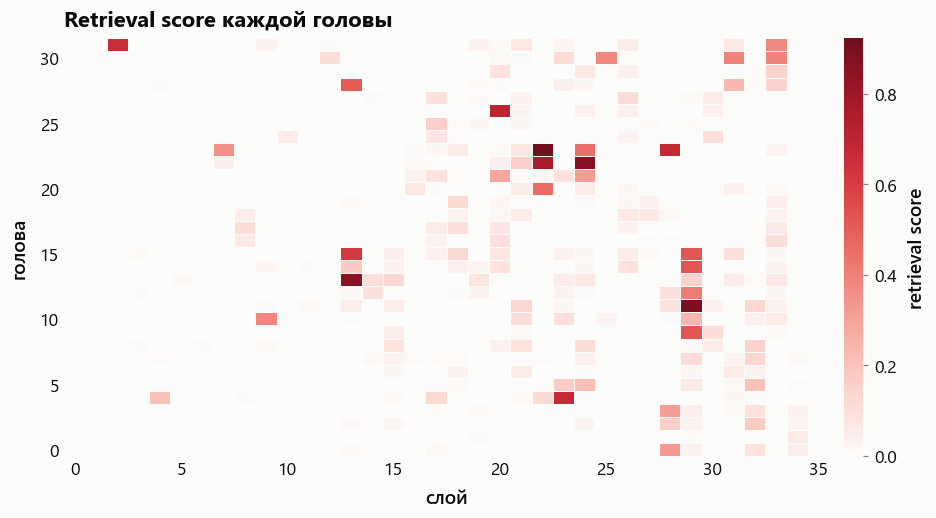

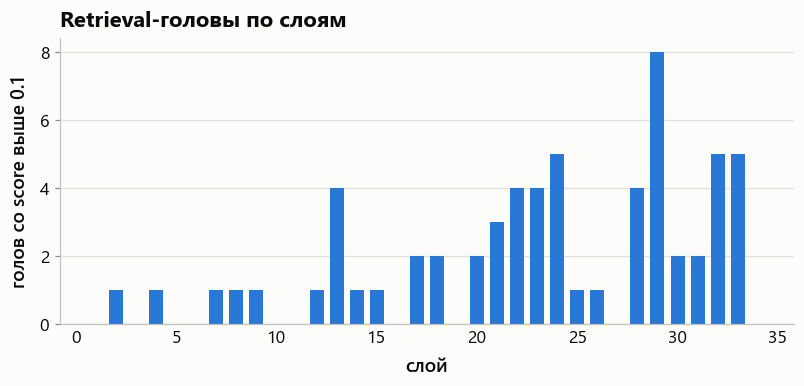

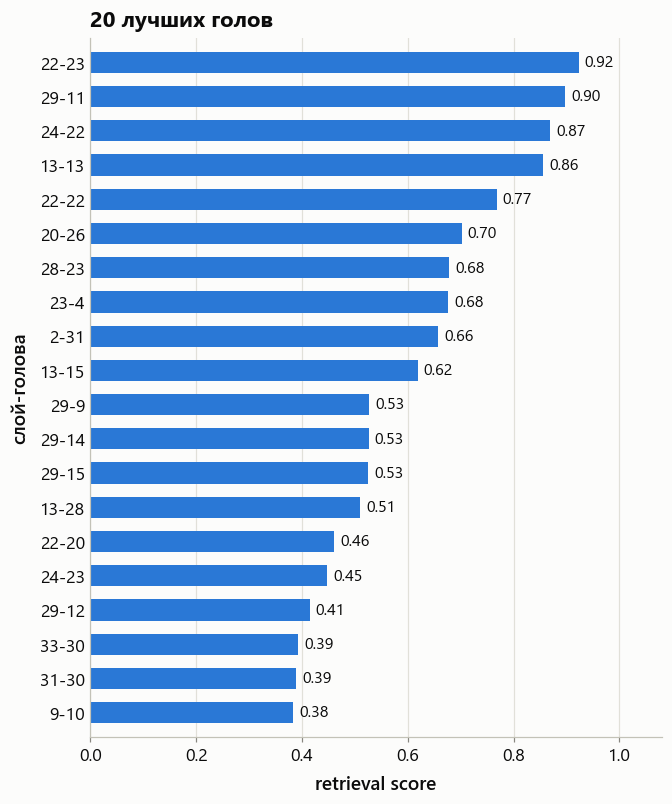

In [7]:
show(plots.head_heatmap(score, heads.layers, title="Retrieval score каждой головы"), "head_heatmap")
show(plots.layer_profile(score, heads.layers, THRESHOLD, title="Retrieval-головы по слоям"), "layer_profile")
show(plots.top_heads(ranking, k=20, threshold=THRESHOLD, title="20 лучших голов"), "top_heads")

In [8]:
ranking.head(20).round(3)

,head,layer,score,frequency
rank,,,,
1,22-23,22,0.923,1.000
2,29-11,29,0.897,1.000
3,24-22,24,0.868,1.000
4,13-13,13,0.855,1.000
5,22-22,22,0.768,1.000
6,20-26,20,0.702,0.997
7,28-23,28,0.678,1.000
8,23-4,23,0.676,1.000
9,2-31,2,0.657,1.000


## 2. Маскирование

Другая игла (про Сан-Франциско), 20 длин × 10 глубин = 200 примеров на прогон. Головы отключаются по рейтингу детекции (`copy_count`): лучшие, случайные россыпью, случайные целыми группами.

**Метрики ответа.** ROUGE-n recall — доля n-грамм эталона, которые есть в ответе (со стеммингом, в процентах):

| Метрика | Что считается | В эталоне этой задачи |
|---|---|---|
| ROUGE-1 recall | отдельные слова, порядок не важен — метрика статьи | 12 слов |
| ROUGE-2 recall | пары соседних слов (двуграммы) | 11 двуграмм |
| ROUGE-3 recall | тройки соседних слов (триграммы) | 10 триграмм |

Эталон: `eat a sandwich and sit in Dolores Park on a sunny day`. Двуграммы и триграммы требуют, чтобы слова стояли рядом и в том же порядке, поэтому случайные совпадения служебных слов (`a`, `and`, `in`, `on`) их не набирают.

**Критерии на этих метриках** (ответ либо проходит, либо нет):

| Критерий | Условие | На этой задаче |
|---|---|---|
| успех по ROUGE-1 | ROUGE-1 recall > 50 — критерий статьи | не меньше 7 слов из 12 |
| успех по ROUGE-2 | ROUGE-2 recall > 50 | не меньше 6 двуграмм из 11 |
| успех по ROUGE-3 | ROUGE-3 recall > 50 | не меньше 6 триграмм из 10 |
| точная фраза | эталон стоит в ответе дословно и подряд | все 12 слов подряд |

В таблице ниже: `rouge1`–`rouge3` — средний recall, `success`, `success2`, `success3`, `exact` — доля ответов, прошедших критерий, в процентах.

In [9]:
sweep = data.load_sweep(MASK, limit=LIMIT)
table = data.summary(sweep)
table

,mask,heads,run,samples,rouge1,rouge2,rouge3,success,success2,success3,exact,tokens,truncated
0,none,0,none,200,100.0,100.0,100.0,100.0,100.0,100.0,100.0,37.5,0.0
1,random,20,random20,200,100.0,100.0,100.0,100.0,100.0,100.0,100.0,40.9,0.0
2,random,40,random40,200,99.8,99.7,99.6,100.0,100.0,100.0,99.0,33.0,0.0
3,random,60,random60,200,100.0,100.0,100.0,100.0,100.0,100.0,100.0,49.3,2.0
4,random,80,random80,200,99.1,98.5,98.5,98.5,98.5,98.5,98.5,44.0,2.5
5,random,100,random100,200,99.9,99.8,99.8,100.0,100.0,100.0,99.5,52.4,5.0
6,random,120,random120,200,99.0,98.5,98.5,98.5,98.5,98.5,98.5,44.1,0.0
7,random_groups,20,groups20,200,100.0,100.0,100.0,100.0,100.0,100.0,100.0,43.9,0.0
8,random_groups,40,groups40,200,100.0,100.0,100.0,100.0,100.0,100.0,100.0,39.6,0.0
9,random_groups,60,groups60,200,100.0,100.0,100.0,100.0,100.0,100.0,100.0,52.2,0.0


### 2.1. Качество от числа отключённых голов (рис. 7 статьи)

Полоса вокруг линии — 95% интервал среднего по 200 примерам.

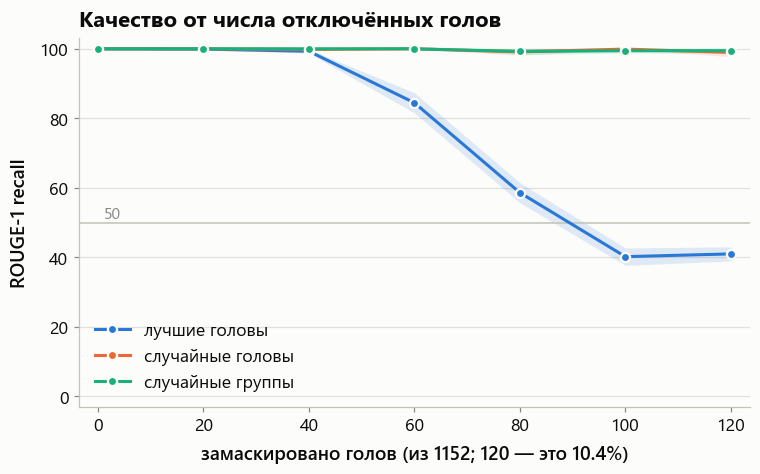

In [10]:
show(plots.mask_curve(sweep, "rouge1_recall", total_heads=total_heads, threshold=50, title="Качество от числа отключённых голов"), "mask_curve_rouge")

#### Слова, двуграммы, триграммы

Средний recall по трём метрикам. Горизонтальная линия — порог критерия (50).

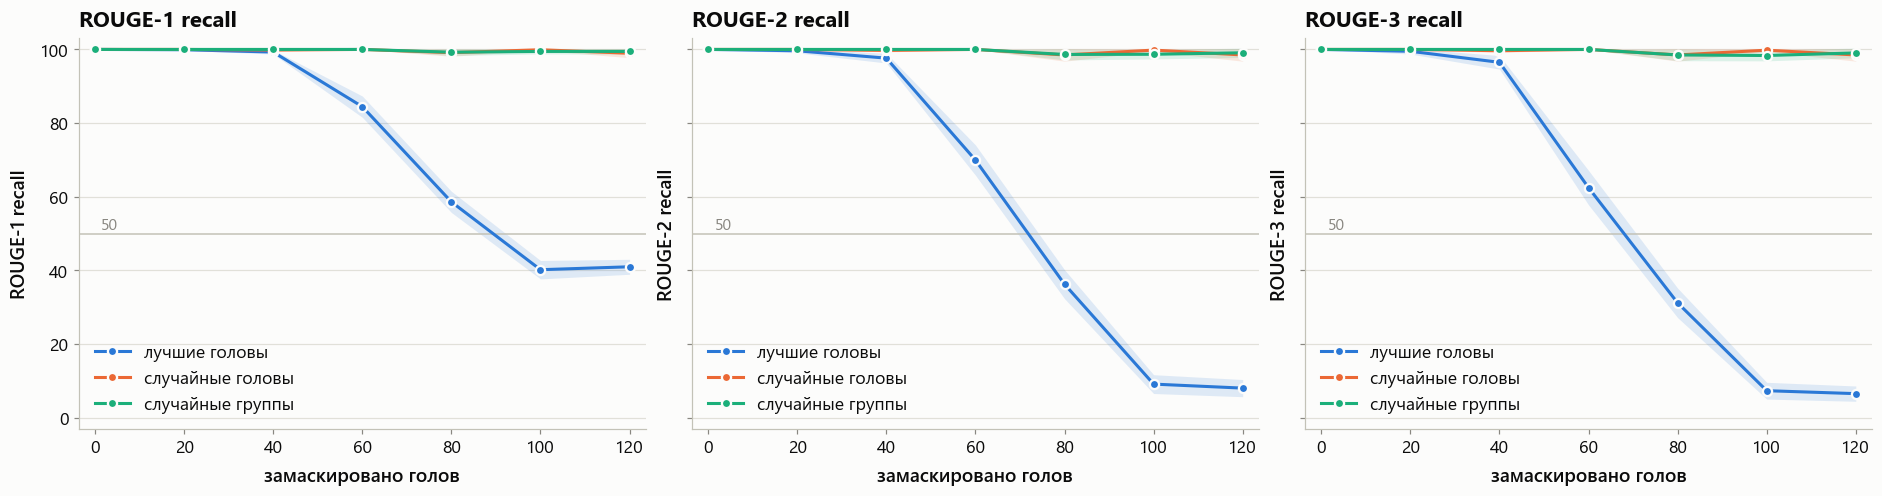

In [11]:
fig, axes = plt.subplots(1, 3, figsize=style.size(17, 4.4), sharey=True)
for ax, n in zip(axes, (1, 2, 3)):
    plots.mask_curve(sweep, f"rouge{n}_recall", threshold=50, ax=ax, title=f"ROUGE-{n} recall")
show(axes, "mask_curve_ngrams")

#### Критерии

Доля ответов, прошедших критерий: успех по ROUGE-1, ROUGE-2, ROUGE-3. Затем все критерии на одном рисунке для маски лучших голов — от самого мягкого к самому строгому.

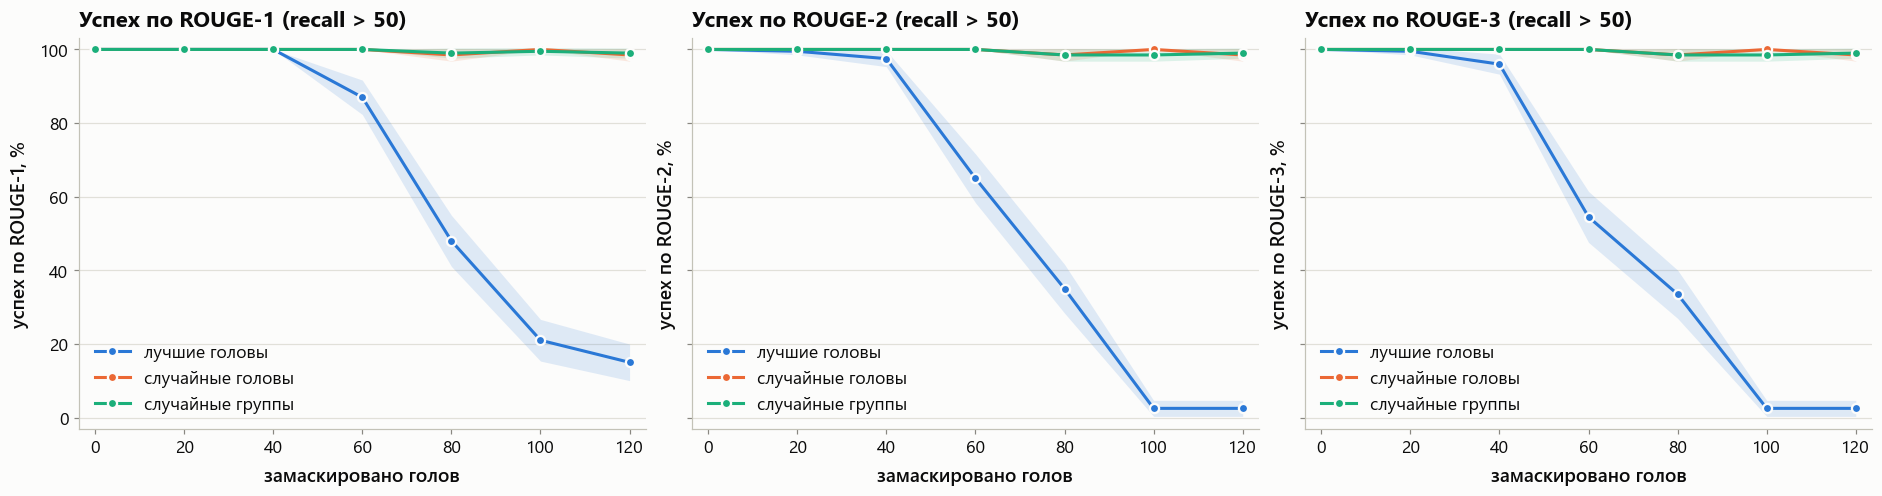

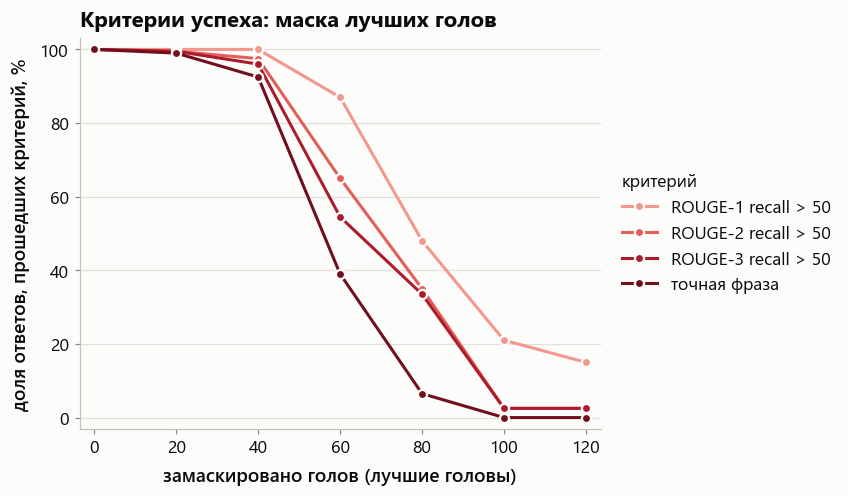

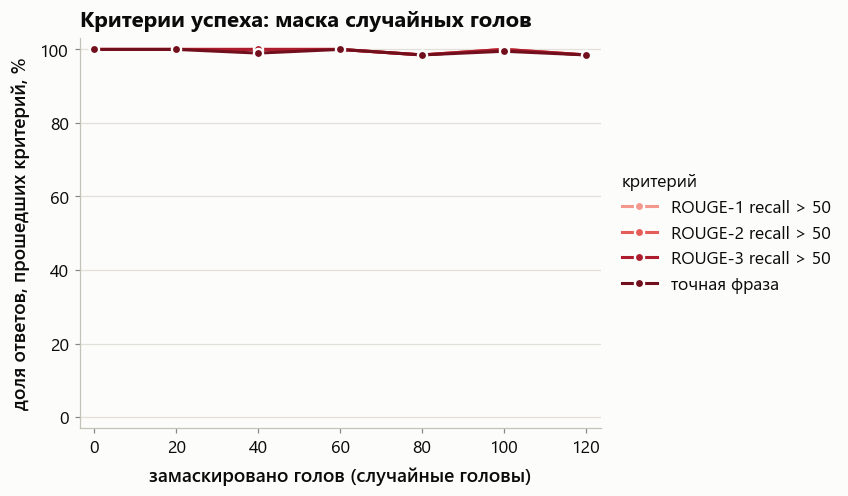

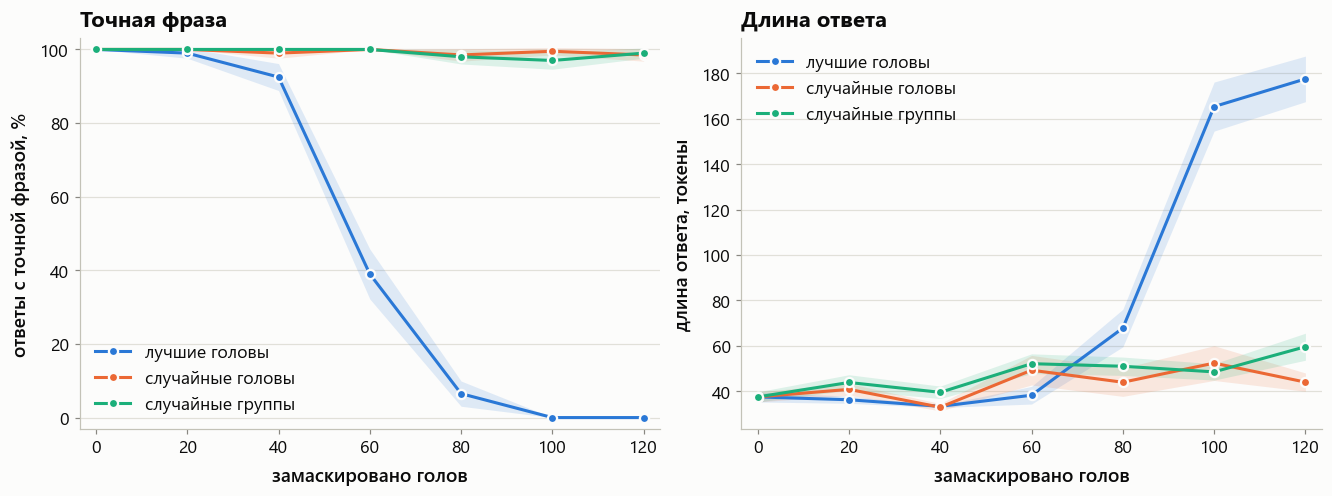

In [12]:
fig, axes = plt.subplots(1, 3, figsize=style.size(17, 4.4), sharey=True)
for ax, n in zip(axes, (1, 2, 3)):
    plots.mask_curve(sweep, data.success_column(n), ax=ax, title=f"Успех по ROUGE-{n} (recall > 50)")
show(axes, "mask_curve_criteria")

show(plots.criteria_curve(sweep, "top", title="Критерии успеха: маска лучших голов"), "criteria_top")
show(plots.criteria_curve(sweep, "random", title="Критерии успеха: маска случайных голов"), "criteria_random")

fig, axes = plt.subplots(1, 2, figsize=style.size(12, 4.4))
plots.mask_curve(sweep, "exact", ax=axes[0], title="Точная фраза")
plots.mask_curve(sweep, "n_tokens", ax=axes[1], title="Длина ответа")
show(axes, "mask_curve_other")

In [13]:
# числом: средний recall и доля ответов, прошедших критерий (%), по видам маски
names = {"rouge1_recall": "ROUGE-1", "rouge2_recall": "ROUGE-2", "rouge3_recall": "ROUGE-3",
         "success": "ROUGE-1 > 50", "success2": "ROUGE-2 > 50", "success3": "ROUGE-3 > 50", "exact": "точная фраза"}
numbers = sweep[sweep["mask"] != "none"].assign(маска=lambda d: d["mask"].map(style.LABELS)).groupby(["маска", "heads"])[list(names)].mean()
numbers[list(names)[3:]] *= 100
numbers.round(1).rename(columns=names)

ROUGE-1  ROUGE-2  ROUGE-3  ROUGE-1 > 50  ROUGE-2 > 50  \
маска            heads                                                          
лучшие головы    20        99.9     99.6     99.5         100.0          99.5   
                 40        99.3     97.6     96.5         100.0          97.5   
                 60        84.5     70.0     62.4          87.0          65.0   
                 80        58.6     36.2     31.2          48.0          35.0   
                 100       40.2      9.1      7.3          21.0           2.5   
                 120       41.0      8.0      6.5          15.0           2.5   
случайные головы 20       100.0    100.0    100.0         100.0         100.0   
                 40        99.8     99.7     99.6         100.0         100.0   
                 60       100.0    100.0    100.0         100.0         100.0   
                 80        99.1     98.5     98.5          98.5          98.5   
                 100       99.9     99.8     99.8         100.0         100.0   
                 120       99.0     98.5     98.5          98.5          98.5   
случайные группы 20       100.0    100.0    100.0         100.0         100.0   
                 40       100.0    100.0    100.0         100.0         100.0   
                 60       100.0    100.0    100.0         100.0         100.0   
                 80        99.2     98.6     98.5          99.0          98.5   
                 100       99.5     98.7     98.4          99.5          98.5   
                 120       99.5     99.1     99.0          99.0          99.0   

                        ROUGE-3 > 50  точная фраза  
маска            heads                              
лучшие головы    20             99.5          99.0  
                 40             96.0          92.5  
                 60             54.5          39.0  
                 80             33.5           6.5  
                 100             2.5           0.0  
                 120             2.5           0.0  
случайные головы 20            100.0         100.0  
                 40            100.0          99.0  
                 60            100.0         100.0  
                 80             98.5          98.5  
                 100           100.0          99.5  
                 120            98.5          98.5  
случайные группы 20            100.0         100.0  
                 40            100.0         100.0  
                 60            100.0         100.0  
                 80             98.5          98.0  
                 100            98.5          97.0  
                 120            99.0          99.0

### 2.2. Карты «длина × глубина» (рис. 1 статьи)

Число в заголовке панели — среднее значение метрики по прогону. Сначала ROUGE-1, затем те же карты по двуграммам и триграммам.

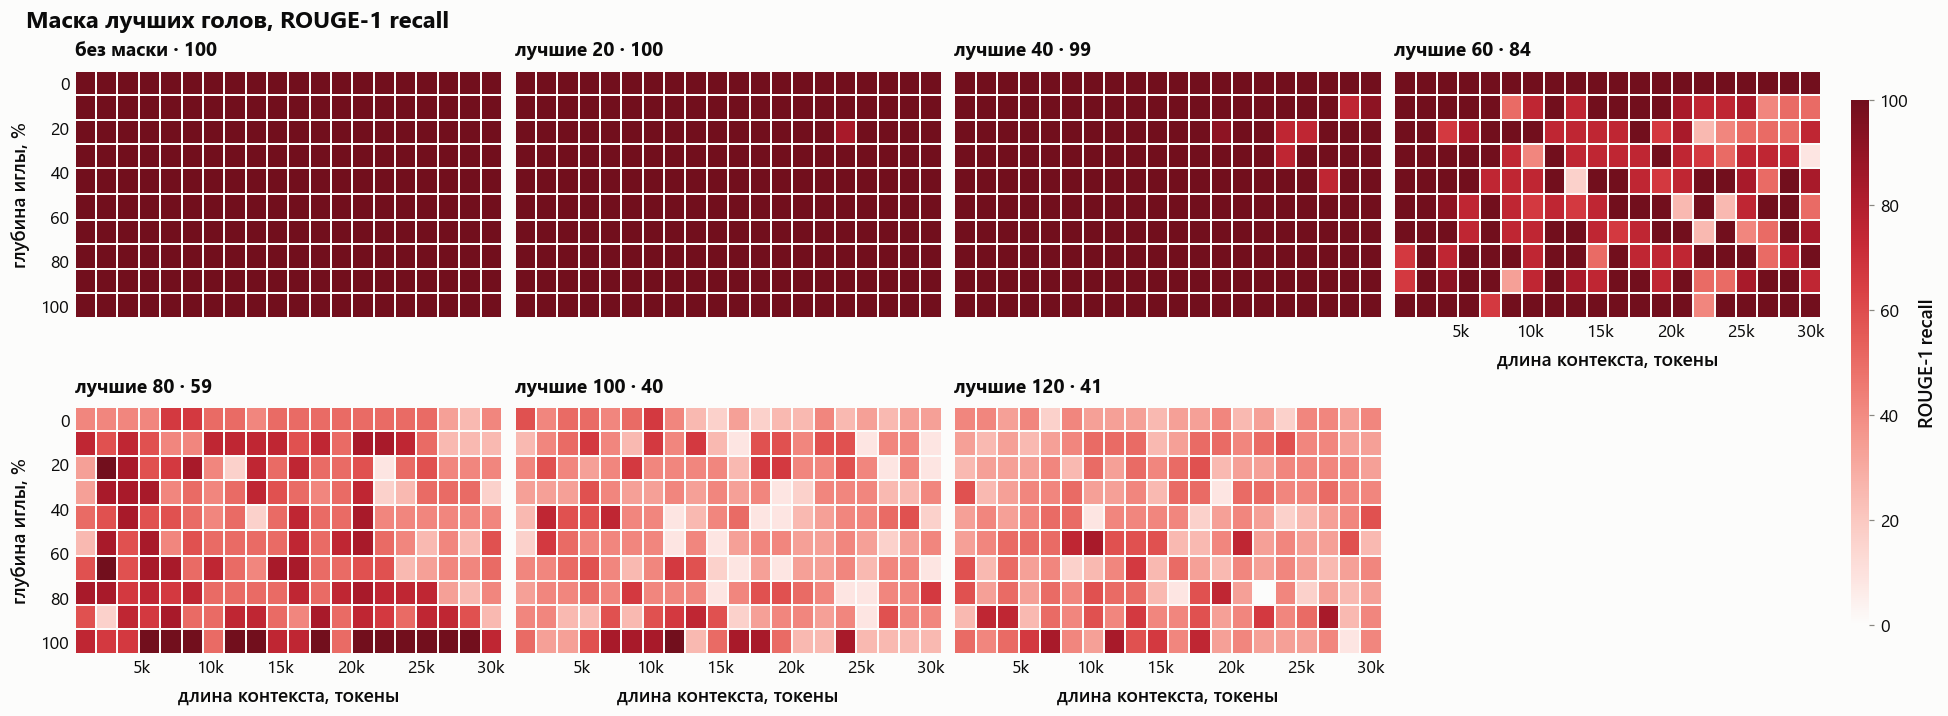

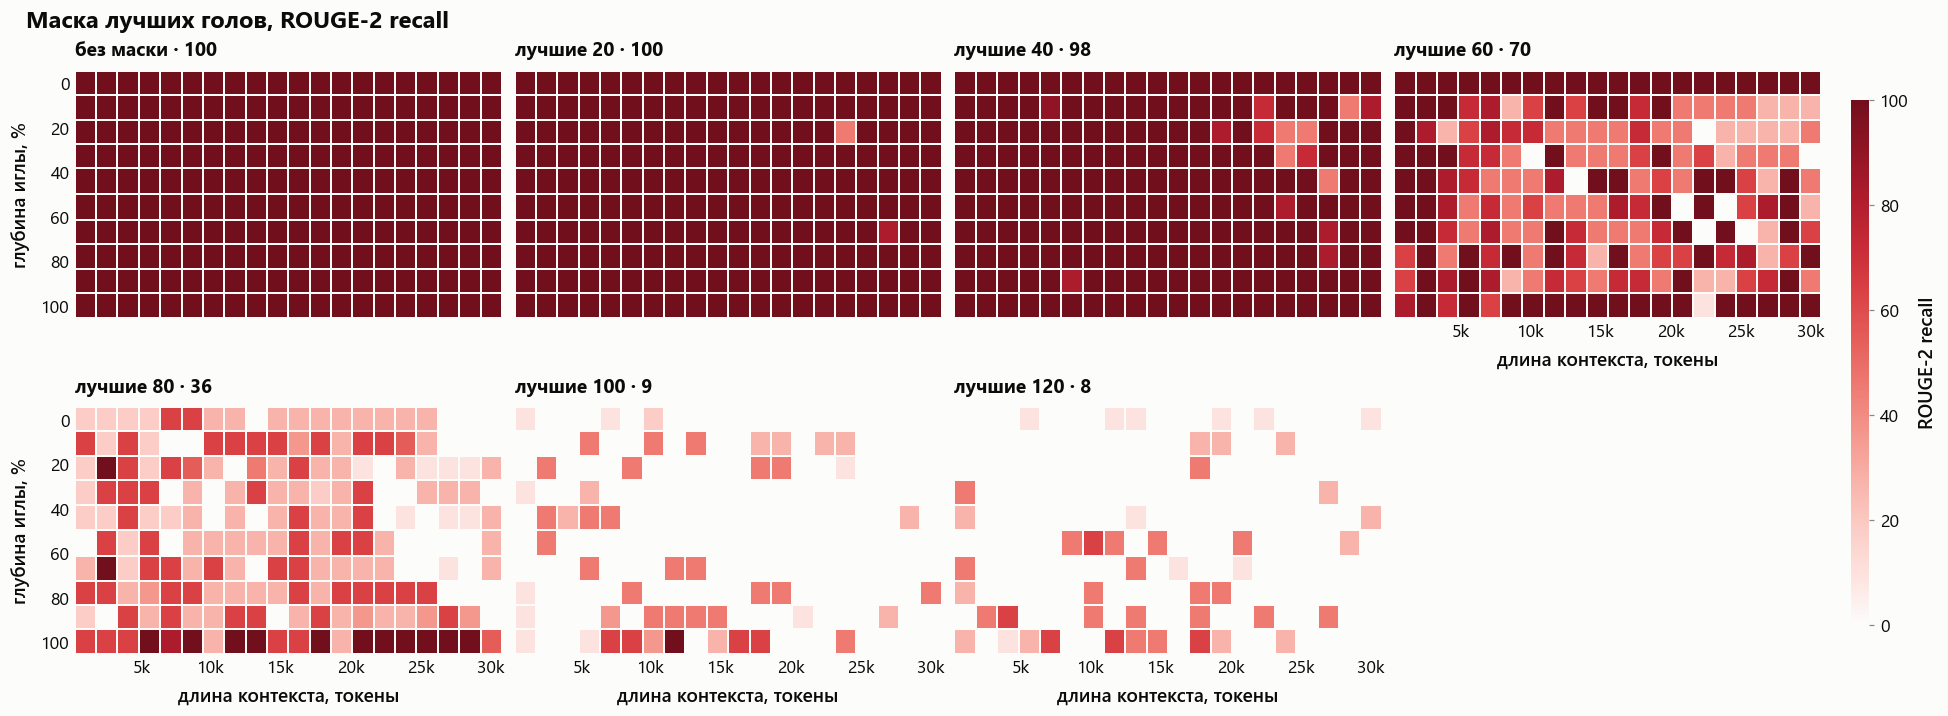

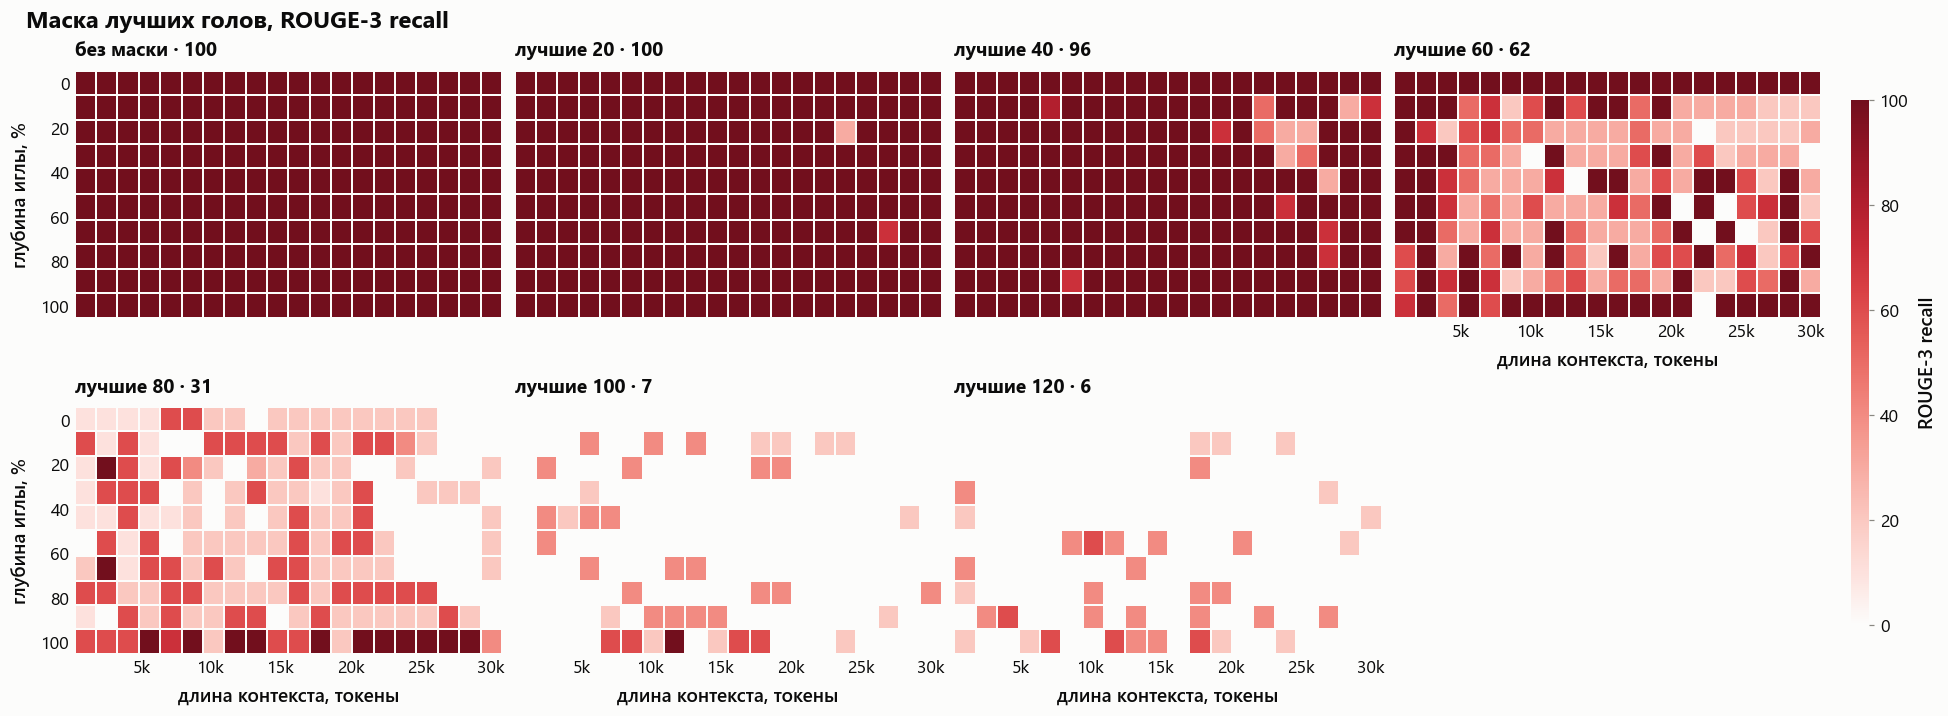

In [14]:
counts = sorted(sweep.loc[sweep["mask"] == "top", "heads"].unique())
show(plots.niah_grid(sweep, {"без маски": "none"} | {f"лучшие {k}": f"top{k}" for k in counts}, columns=4,
                     title="Маска лучших голов, ROUGE-1 recall"), "niah_top")
for n in (2, 3):
    show(plots.niah_grid(sweep, {"без маски": "none"} | {f"лучшие {k}": f"top{k}" for k in counts}, value=f"rouge{n}_recall", columns=4,
                         title=f"Маска лучших голов, ROUGE-{n} recall"), f"niah_top_rouge{n}")

#### Случайные головы

Те же карты для масок случайных голов (россыпью) по трём метрикам, затем сравнение трёх видов маски при наибольшем числе голов.

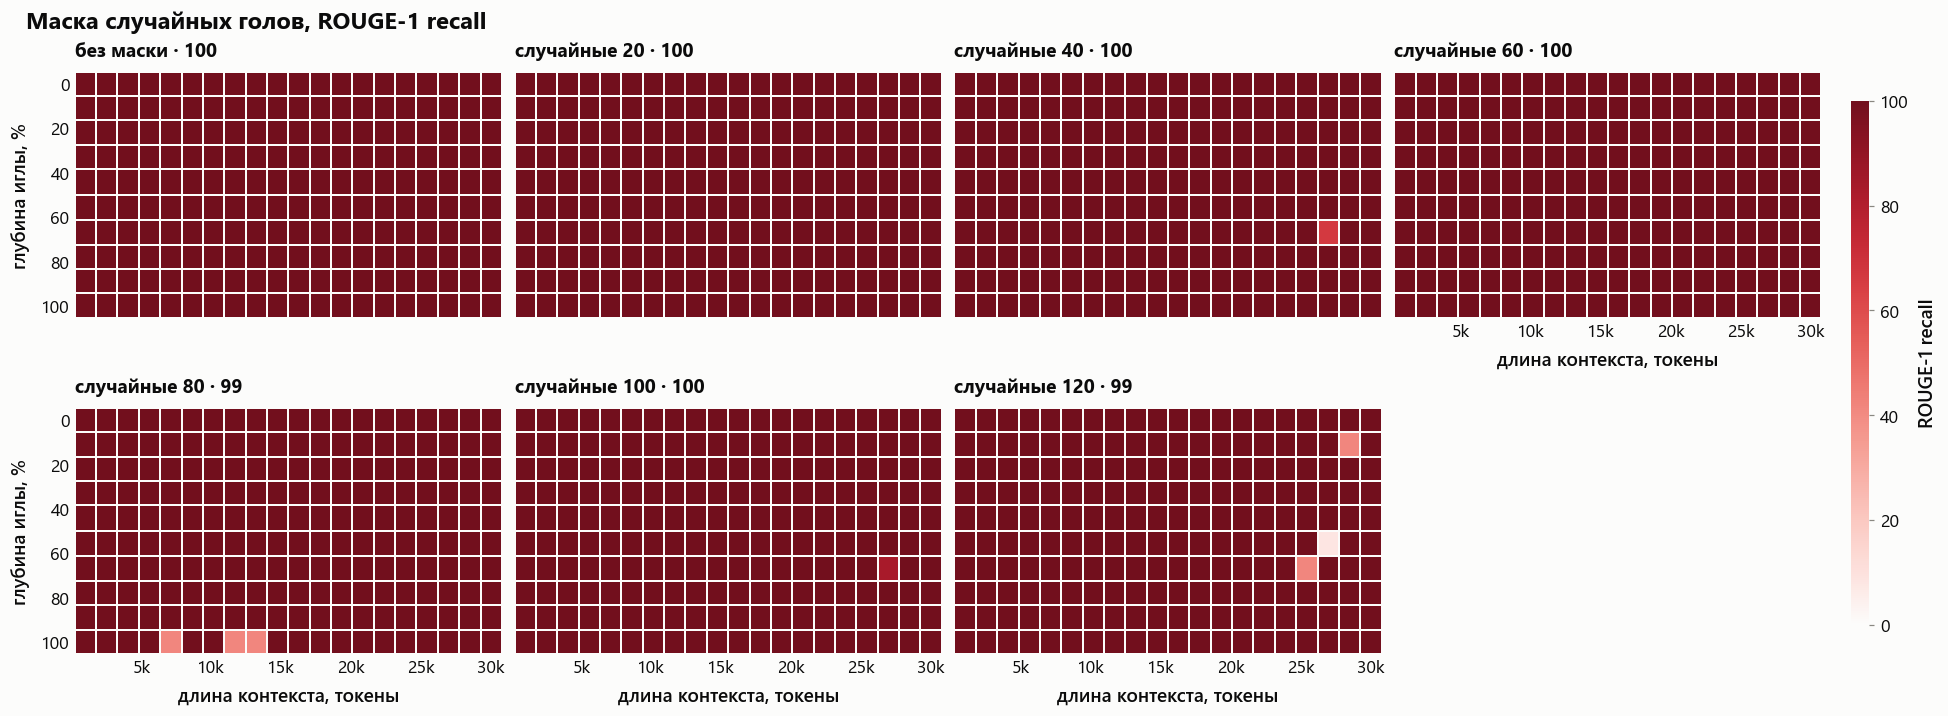

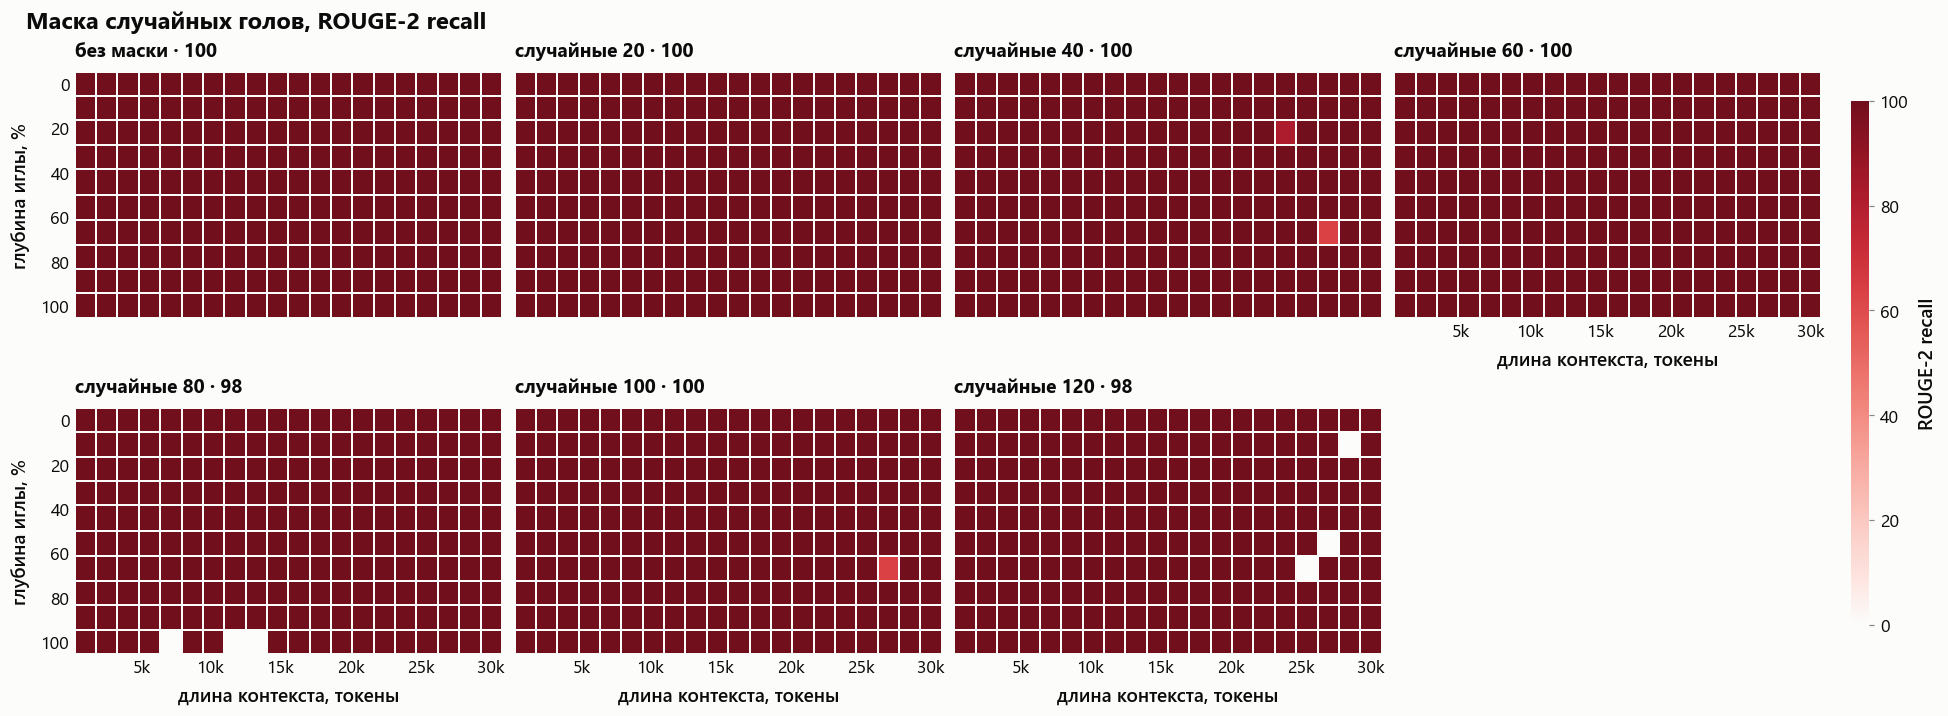

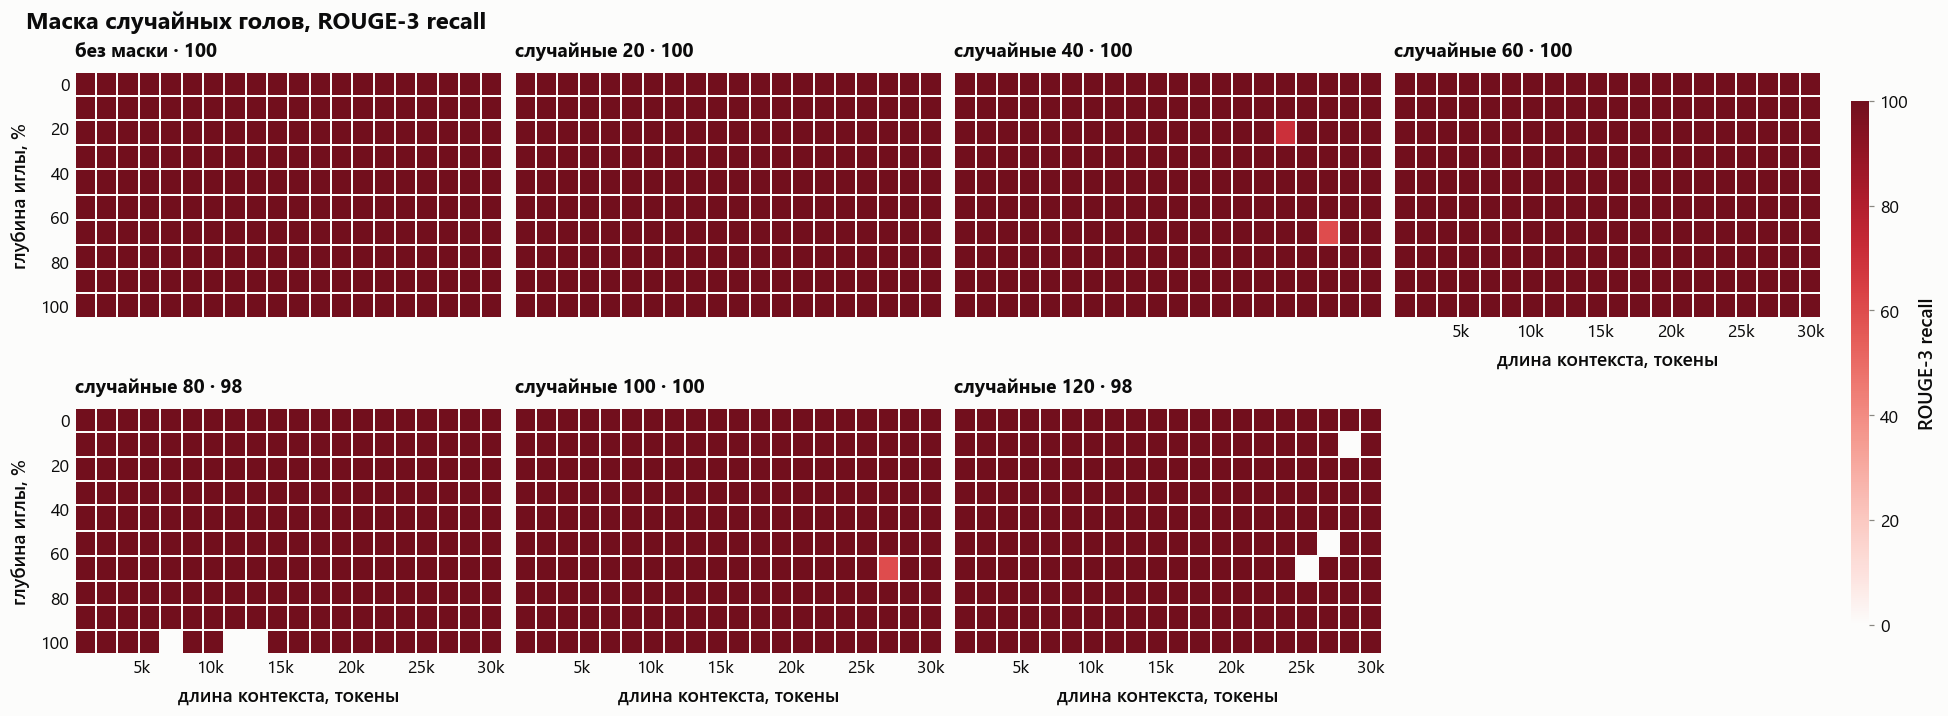

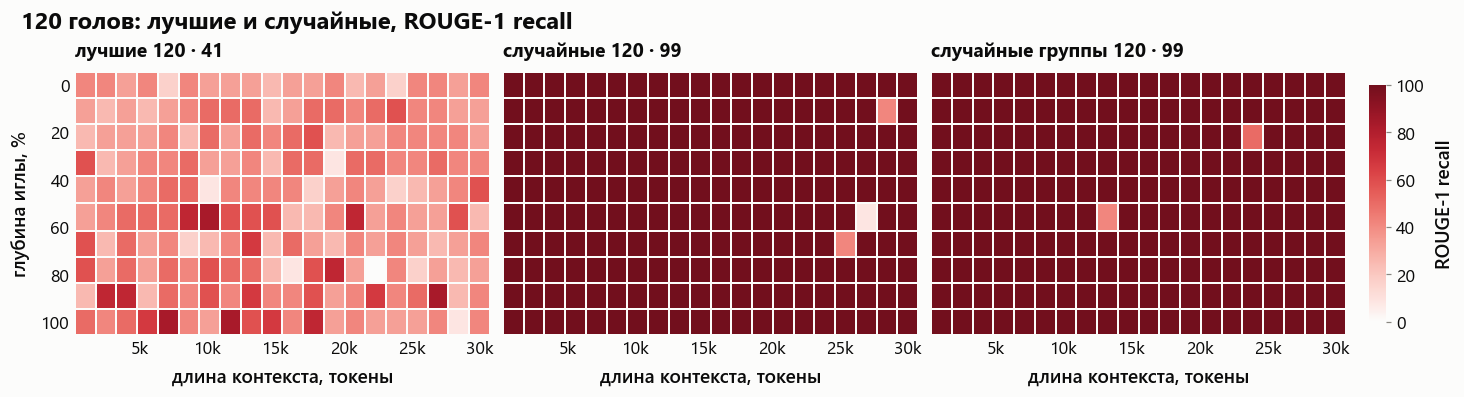

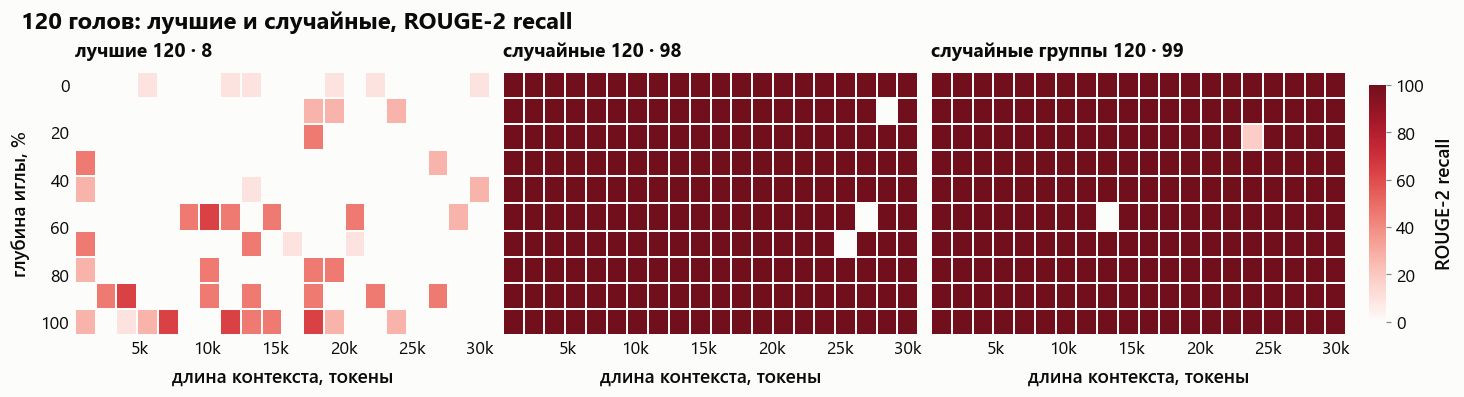

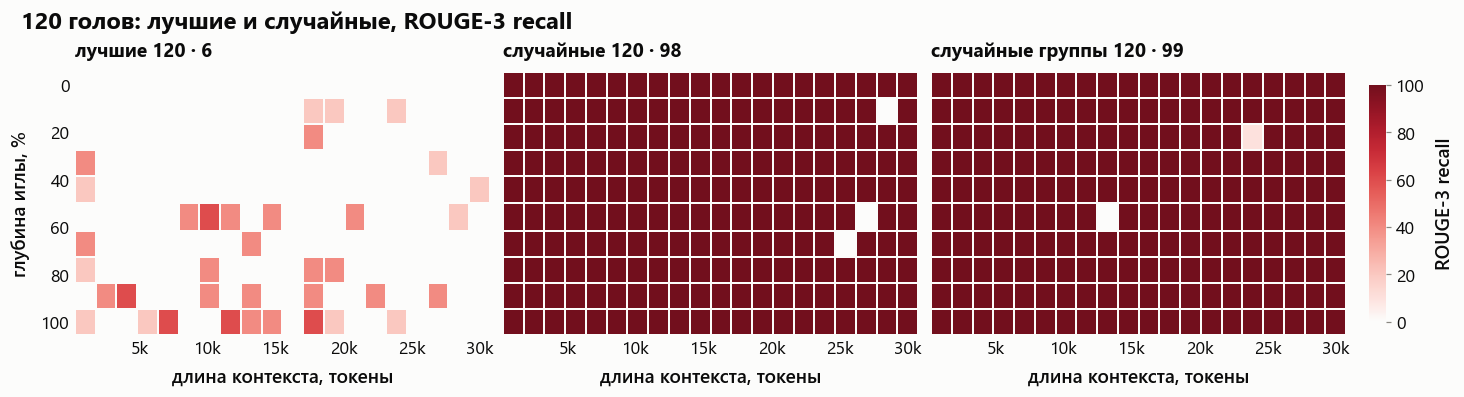

In [15]:
for n in (1, 2, 3):
    show(plots.niah_grid(sweep, {"без маски": "none"} | {f"случайные {k}": f"random{k}" for k in counts}, value=f"rouge{n}_recall", columns=4,
                         title=f"Маска случайных голов, ROUGE-{n} recall"), f"niah_random_rouge{n}")
most = counts[-1]
for n in (1, 2, 3):
    show(plots.niah_grid(sweep, {f"лучшие {most}": f"top{most}", f"случайные {most}": f"random{most}", f"случайные группы {most}": f"groups{most}"},
                         value=f"rouge{n}_recall", title=f"{most} голов: лучшие и случайные, ROUGE-{n} recall"), f"niah_top_vs_random_rouge{n}")

### 2.3. Зависимость от длины и глубины

Точки стоят на настоящих значениях сетки, в каждой 10–20 примеров.

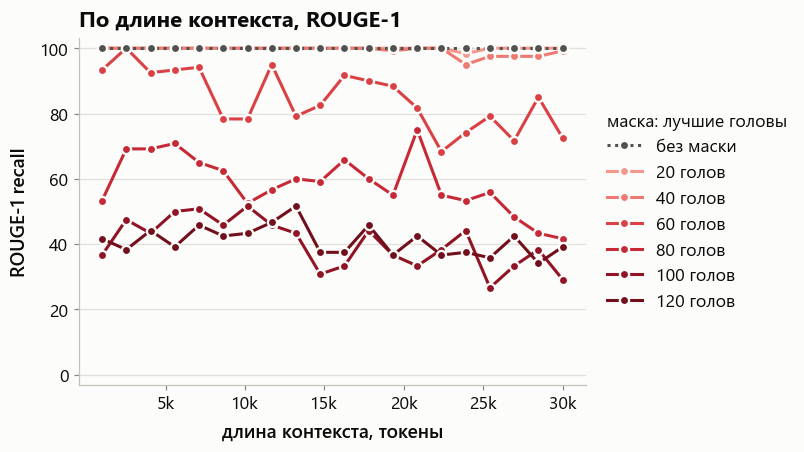

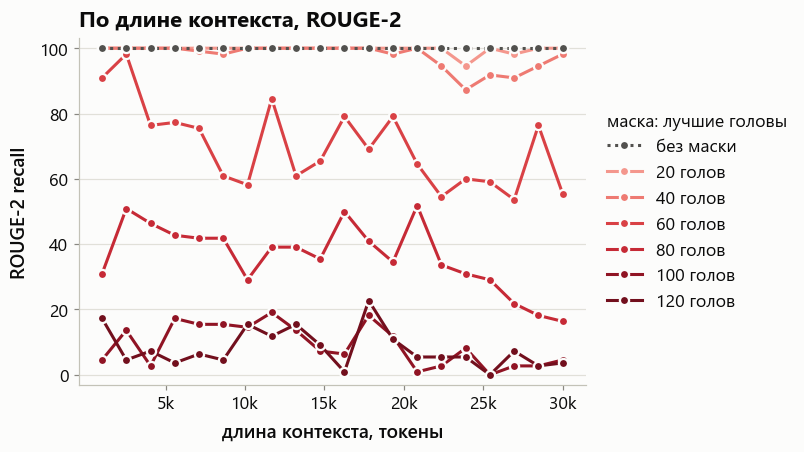

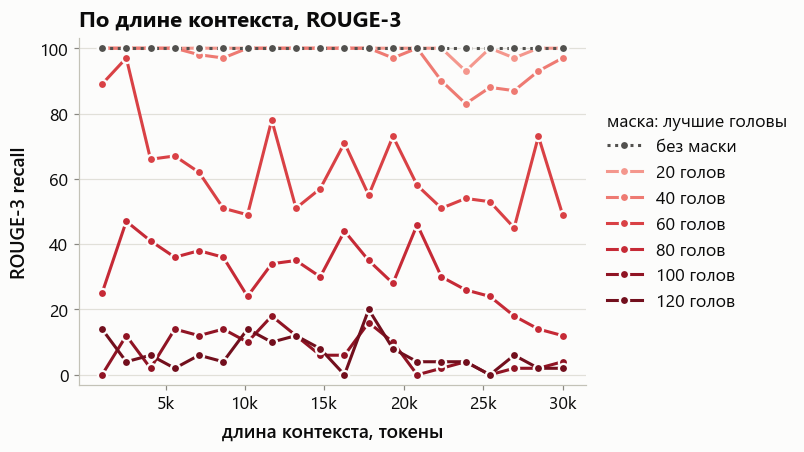

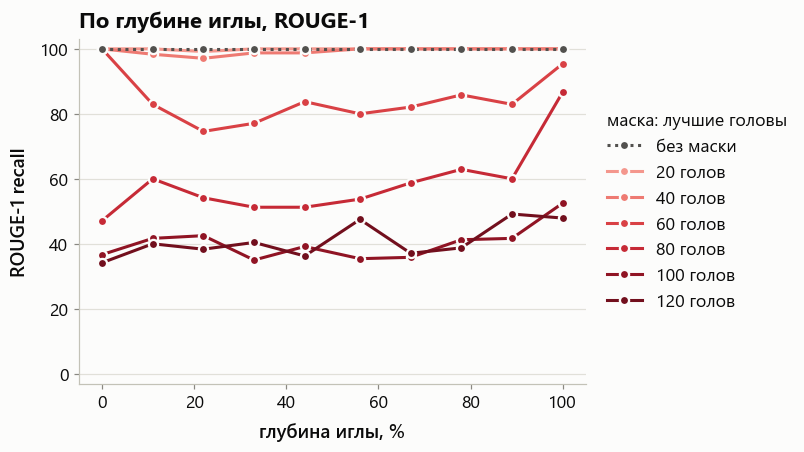

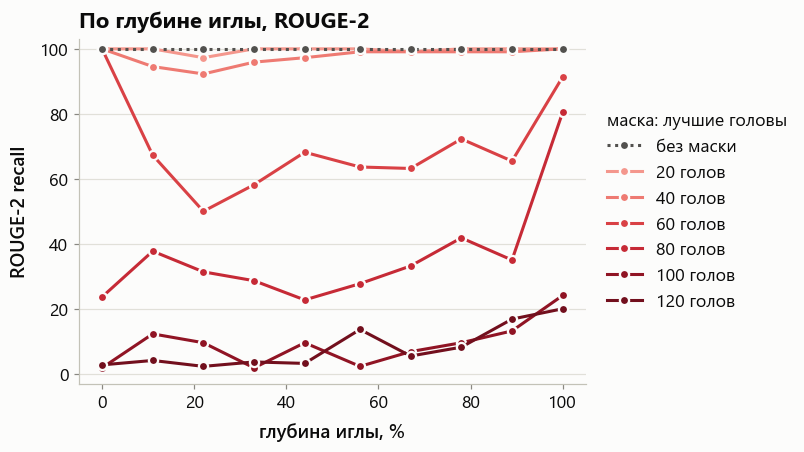

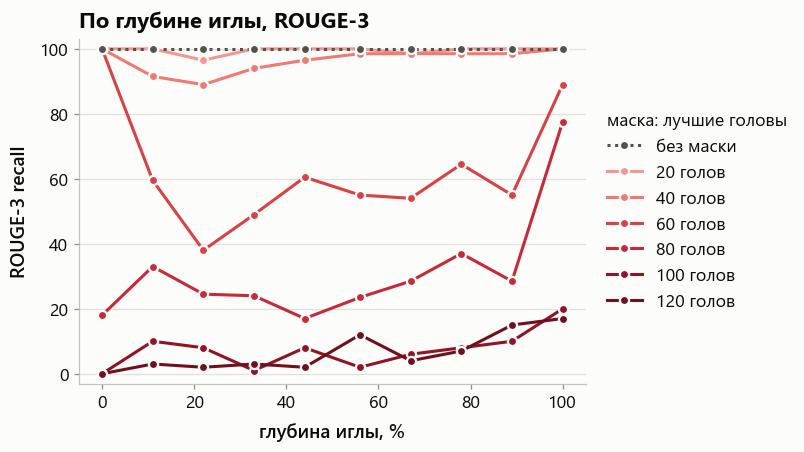

In [16]:
for n in (1, 2, 3):
    show(plots.score_by(sweep, "context_length", kind="top", value=f"rouge{n}_recall", title=f"По длине контекста, ROUGE-{n}"), f"by_length_rouge{n}")
for n in (1, 2, 3):
    show(plots.score_by(sweep, "depth_percent", kind="top", value=f"rouge{n}_recall", title=f"По глубине иглы, ROUGE-{n}"), f"by_depth_rouge{n}")

### 2.4. Что происходит с ответами (по мотивам рис. 9 статьи)

Каждый ответ относится ровно к одному типу. Условия проверяются сверху вниз, ответ получает первый подошедший тип. Типы строятся по одной из трёх метрик — ROUGE-1, ROUGE-2 или ROUGE-3; правило одно и то же, меняется только единица счёта (слова, двуграммы, триграммы).

| Тип | Критерий (n = 1, 2, 3) | Что это значит |
|---|---|---|
| точная фраза | эталон стоит в ответе дословно и подряд; регистр и пунктуация не учитываются | модель списала ответ из иглы целиком |
| успех без точной фразы | дословной фразы нет, но ROUGE-n recall > 50 | больше половины n-грамм эталона есть, но фраза оборвана, переставлена или пересказана |
| неполный ответ | ROUGE-n recall от 0 до 50 | найдена только часть ответа — «incomplete retrieval» статьи |
| нет совпадений | ROUGE-n recall = 0 | ни одной n-граммы эталона |

По словам (n = 1) в «неполный ответ» попадает и ответ не по игле, в котором случайно совпали служебные слова эталона, поэтому тип «нет совпадений» там почти всегда пуст. По двуграммам и триграммам такие ответы уходят в «нет совпадений».

Ниже — критерии с числом ответов и примером из одного прогона, для каждой из трёх метрик.

In [17]:
RUN = "top80"   # прогон, из которого берутся примеры
part = sweep[sweep["run"] == RUN]
print("эталон:", part["reference"].iloc[0])

def type_table(n):
    column, rows = data.type_column(n), []
    for kind in data.ANSWER_TYPES:
        found = part[part[column] == kind]
        row = found.loc[found["n_tokens"].idxmin()] if len(found) else None   # самый короткий ответ этого типа
        rows.append({"метрика": f"ROUGE-{n}", "тип": plots.TYPE_LABELS[kind], "критерий": data.type_criteria(n)[kind], f"ответов в {RUN}": len(found),
                     "recall примера": round(row[f"rouge{n}_recall"], 1) if row is not None else "—", "пример ответа": row["response"] if row is not None else "—"})
    return pd.DataFrame(rows)

pd.set_option("display.max_colwidth", 400)
pd.concat([type_table(n) for n in (1, 2, 3)]).set_index(["метрика", "тип"])

эталон: eat a sandwich and sit in Dolores Park on a sunny day


критерий  \
метрика тип                                                                                                              
ROUGE-1 точная фраза                      эталон стоит в ответе дословно и подряд; регистр и пунктуация не учитываются   
        успех без точной фразы      дословной фразы нет, но ROUGE-1 recall > 50: в ответе больше половины слов эталона   
        неполный ответ                       ROUGE-1 recall от 0 до 50: есть часть слов эталона, но не больше половины   
        нет совпадений                                        ROUGE-1 recall = 0: ни одного совпадения слов с эталоном   
ROUGE-2 точная фраза                      эталон стоит в ответе дословно и подряд; регистр и пунктуация не учитываются   
        успех без точной фразы  дословной фразы нет, но ROUGE-2 recall > 50: в ответе больше половины двуграмм эталона   
        неполный ответ                   ROUGE-2 recall от 0 до 50: есть часть двуграмм эталона, но не больше половины   
        нет совпадений                                    ROUGE-2 recall = 0: ни одного совпадения двуграмм с эталоном   
ROUGE-3 точная фраза                      эталон стоит в ответе дословно и подряд; регистр и пунктуация не учитываются   
        успех без точной фразы  дословной фразы нет, но ROUGE-3 recall > 50: в ответе больше половины триграмм эталона   
        неполный ответ                   ROUGE-3 recall от 0 до 50: есть часть триграмм эталона, но не больше половины   
        нет совпадений                                    ROUGE-3 recall = 0: ни одного совпадения триграмм с эталоном   

                                ответов в top80 recall примера  \
метрика тип                                                      
ROUGE-1 точная фраза                         13          100.0   
        успех без точной фразы               83           75.0   
        неполный ответ                      104           41.7   
        нет совпадений                        0              —   
ROUGE-2 точная фраза                         13          100.0   
        успех без точной фразы               57           63.6   
        неполный ответ                       94           27.3   
        нет совпадений                       36            0.0   
ROUGE-3 точная фраза                         13          100.0   
        успех без точной фразы               54           60.0   
        неполный ответ                       89           20.0   
        нет совпадений                       44            0.0   

                                                                                                                              пример ответа  
метрика тип                                                                                                                                  
ROUGE-1 точная фраза            Based on the content of the book, the answer is: **Eat a sandwich and sit in Dolores Park on a sunny day.**  
        успех без точной фразы              Based on the content of the book, the best answer is to eat a sandwich and sit in Dolores Park.  
        неполный ответ                                                         The best answer is to sit in Dolores Park and enjoy the sun.  
        нет совпадений                                                                                                                    —  
ROUGE-2 точная фраза            Based on the content of the book, the answer is: **Eat a sandwich and sit in Dolores Park on a sunny day.**  
        успех без точной фразы              Based on the content of the book, the best answer is to eat a sandwich and sit in Dolores Park.  
        неполный ответ                                                         The best answer is to sit in Dolores Park and enjoy the sun.  
        нет совпадений                                                The best answer, based on the content of the book, is to take a hike.  
ROUGE-3 точная фраза            Based on the content of 

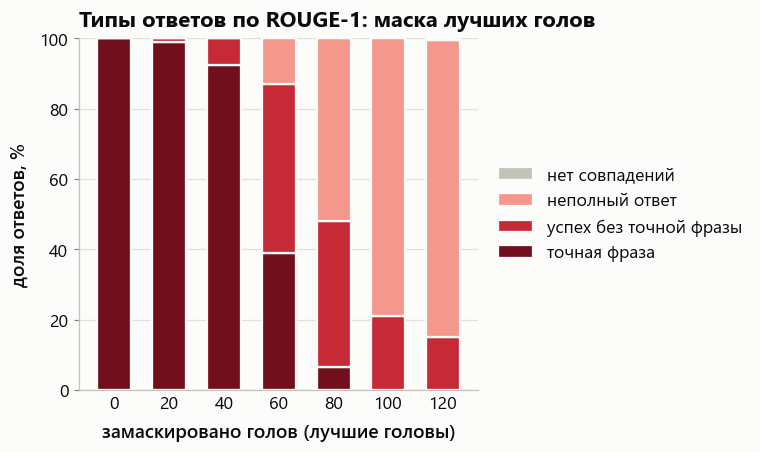

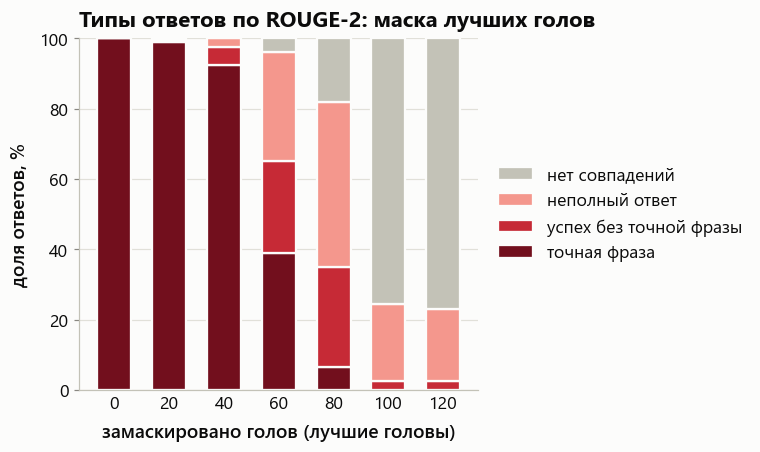

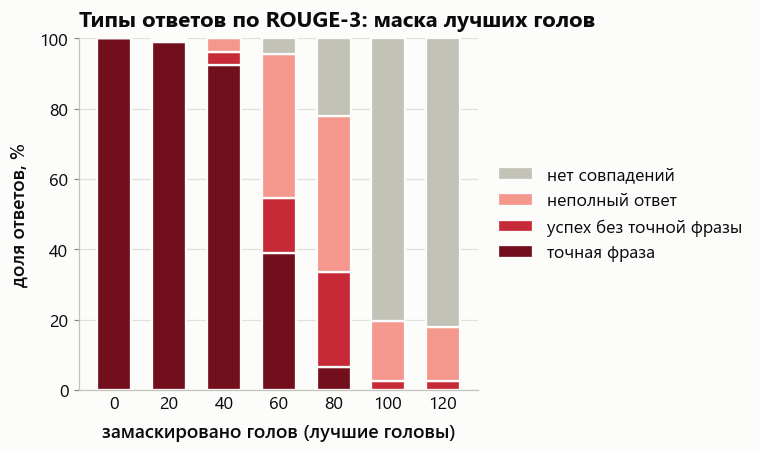

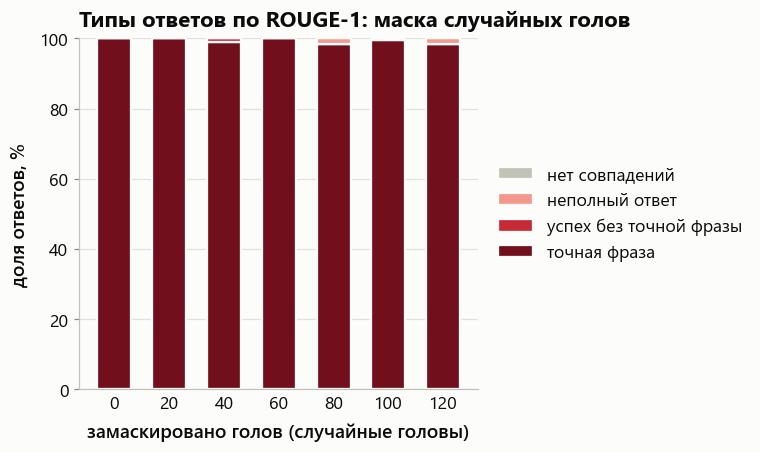

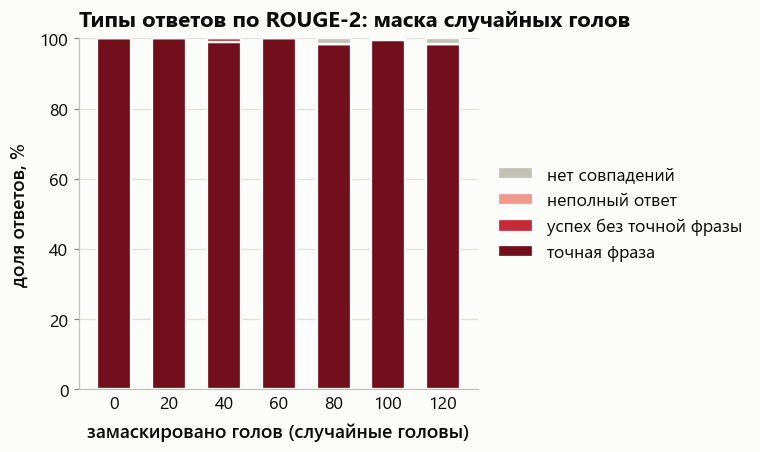

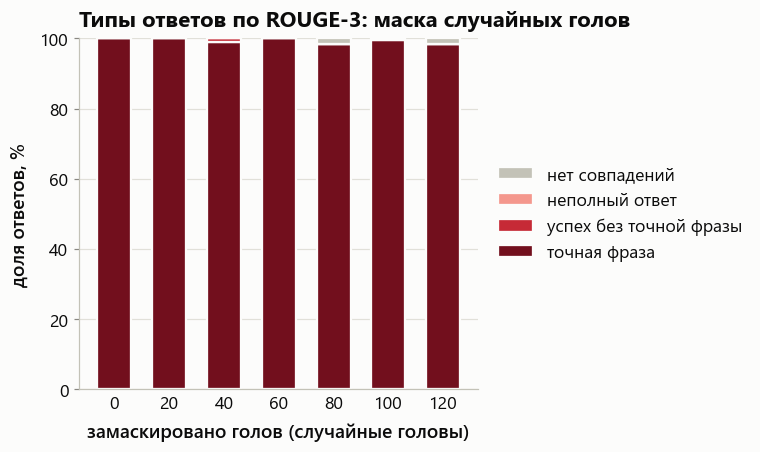

In [18]:
for n in (1, 2, 3):
    show(plots.answer_types(sweep, "top", n=n, title=f"Типы ответов по ROUGE-{n}: маска лучших голов"), f"answer_types_top_rouge{n}")
for n in (1, 2, 3):
    show(plots.answer_types(sweep, "random", n=n, title=f"Типы ответов по ROUGE-{n}: маска случайных голов"), f"answer_types_random_rouge{n}")

### 2.5. Перефразы, замены и формы слов

ROUGE и точная фраза сравнивают строки. Здесь ответ разбирается по смыслу: эталон разбит на четыре факта, и для каждого факта смотрим, как он записан в ответе.

| Уровень | Что это | Пример для «eat a sandwich» |
|---|---|---|
| дословно | формулировка эталона | `eat a sandwich` |
| другая форма слова | те же слова в другой форме | `eating a sandwich` |
| близкая замена | синоним или пересказ | `enjoy a meal` |
| нет | факта в ответе нет | — |

Факты эталона: `eat a sandwich`, `sit`, `Dolores Park`, `sunny day`. Списки форм и замен лежат в `vizual/paraphrase.py` (`FACTS`). Они собраны вручную по ответам этих прогонов: это перечень того, что модель действительно писала, а не словарь синонимов. Для другой иглы нужен свой список.

По формулировкам фактов ответ целиком получает одну из шести структур:

| Структура | Условие |
|---|---|
| точная фраза | эталон стоит в ответе дословно и подряд |
| все факты дословно, другой порядок или вставка | все четыре факта дословно, но фраза не совпадает: части переставлены или между ними вставлены слова |
| все факты, часть — формой слова или заменой | все четыре факта есть, хотя бы один не дословно |
| часть фактов, все дословно | часть фактов пропала, оставшиеся дословно — обрезанный ответ |
| часть фактов, есть форма слова или замена | часть фактов пропала, среди оставшихся есть форма слова или замена |
| ни одного факта | ответ не по игле |

In [19]:
worded = paraphrase.annotate(sweep)
facts = list(paraphrase.FACTS[worded["reference"].iloc[0]])
changed = worded[~worded["exact"]]
print(f"ответов: {len(worded)}, без точной фразы: {len(changed)}")
print(f"  с формой слова хотя бы в одном факте: {(changed[facts] == 'form').any(axis=1).sum()}")
print(f"  с близкой заменой хотя бы в одном факте: {(changed[facts] == 'paraphrase').any(axis=1).sum()}")

# что именно написано вместо формулировки эталона
paraphrase.wordings(worded)

ответов: 3800, без точной фразы: 747
  с формой слова хотя бы в одном факте: 7
  с близкой заменой хотя бы в одном факте: 86


,факт,уровень,написано,ответов
0,eat a sandwich,другая форма слова,eating a sandwich,5
1,eat a sandwich,близкая замена,enjoy a meal,9
2,sit,другая форма слова,sitting,3
3,sit,близкая замена,relax,6
4,sit,близкая замена,relaxing,1
5,Dolores Park,близкая замена,the park,28
6,sunny day,близкая замена,in the sun,31
7,sunny day,близкая замена,enjoy the sunshine,12
8,sunny day,близкая замена,enjoy the sun,4
9,sunny day,близкая замена,beautiful weather,2


#### Как строковые метрики оценивают каждую структуру

По всем прогонам маскирования. `фактов` — сколько из четырёх фактов есть в ответе в любой формулировке; столбцы «успех» — доля ответов, прошедших критерий.

In [20]:
by_structure = worded.groupby("structure").agg(ответов=("id", "size"), фактов=("facts_found", "mean"), rouge1=("rouge1_recall", "mean"),
                                               rouge2=("rouge2_recall", "mean"), rouge3=("rouge3_recall", "mean"), успех1=("success", "mean"),
                                               успех2=("success2", "mean"), успех3=("success3", "mean")).reindex(paraphrase.STRUCTURES)
by_structure[["успех1", "успех2", "успех3"]] *= 100
by_structure.round(1).rename(index=paraphrase.STRUCTURE_LABELS)

,ответов,фактов,rouge1,rouge2,rouge3,успех1,успех2,успех3
structure,,,,,,,,
точная фраза,3053,4.0,100.0,100.0,100.0,100.0,100.0,100.0
"все факты дословно, другой порядок или вставка",47,4.0,100.0,77.4,60.0,100.0,100.0,48.9
"все факты, часть — формой слова или заменой",6,4.0,90.3,80.3,70.0,100.0,100.0,83.3
"часть фактов, все дословно",260,2.3,64.6,41.6,33.4,68.1,32.3,31.5
"часть фактов, есть форма слова или замена",86,2.5,55.6,27.7,22.3,55.8,0.0,0.0
ни одного факта,348,0.0,33.7,0.2,0.0,0.0,0.0,0.0


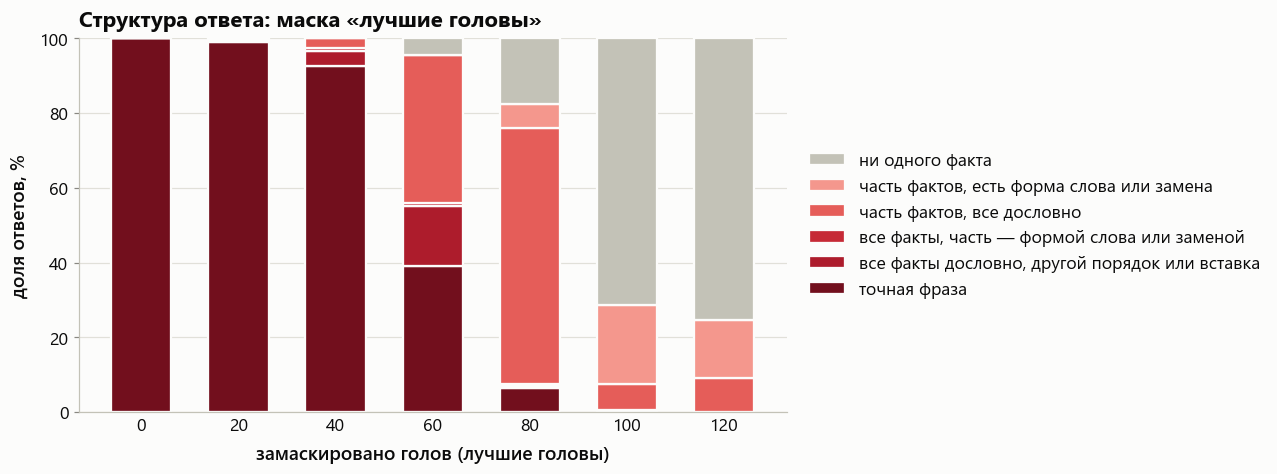

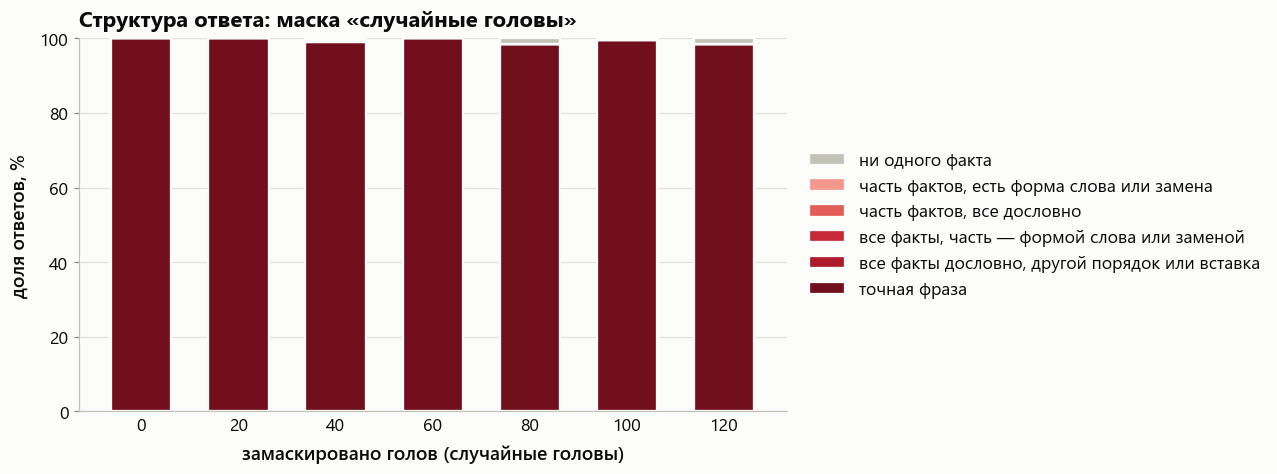

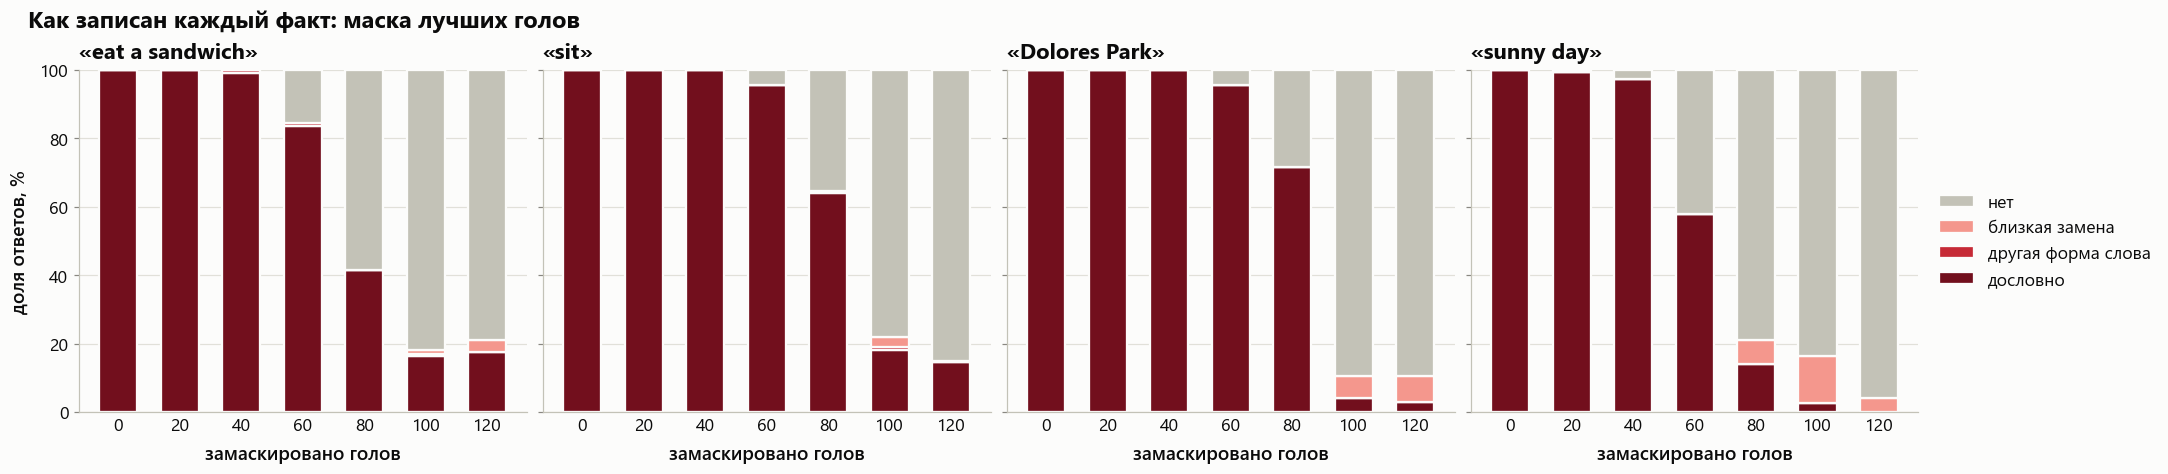

In [21]:
for kind in ("top", "random"):
    ax = plt.subplots(figsize=style.size(11.5, 4.2))[1]   # шире обычного: у легенды длинные подписи
    show(plots.shares(worded, "structure", paraphrase.STRUCTURES, paraphrase.STRUCTURE_LABELS, kind, ax=ax,
                      title=f"Структура ответа: маска «{style.LABELS[kind]}»"), f"structure_{kind}")
show(plots.fact_wordings(worded, facts, paraphrase.LEVELS, paraphrase.LEVEL_LABELS, "top", title="Как записан каждый факт: маска лучших голов"), "fact_wordings_top")

In [22]:
# примеры: по два самых коротких ответа каждой структуры
pd.set_option("display.max_colwidth", 300)
examples = changed.sort_values("n_tokens").groupby("structure").head(2)
examples.assign(структура=examples["structure"].map(paraphrase.STRUCTURE_LABELS)).set_index("структура").loc[
    [paraphrase.STRUCTURE_LABELS[k] for k in paraphrase.STRUCTURES if k in set(examples["structure"])],
    ["run", "rouge1_recall", "rouge2_recall", "rouge3_recall", "response"]].round(0)

,run,rouge1_recall,rouge2_recall,rouge3_recall,response
структура,,,,,
"все факты дословно, другой порядок или вставка",top40,100.0,82.0,70.0,The best thing to do in San Francisco is to sit in Dolores Park on a sunny day and eat a sandwich.
"все факты дословно, другой порядок или вставка",top60,100.0,82.0,70.0,"The best thing to do in San Francisco, based on the text, is to sit in Dolores Park on a sunny day and eat a sandwich."
"все факты, часть — формой слова или заменой",top60,92.0,82.0,70.0,"The best thing to do in San Francisco, based on the content provided, is to sit in Dolores Park on a sunny day after eating a sandwich."
"все факты, часть — формой слова или заменой",top60,92.0,82.0,70.0,"The best thing to do in San Francisco, based on the content provided, is to sit in Dolores Park on a sunny day after eating a sandwich."
"часть фактов, все дословно",top60,33.0,27.0,20.0,The best thing to do in San Francisco is to sit in Dolores Park.
"часть фактов, все дословно",top60,67.0,45.0,30.0,The best thing to do in San Francisco is to sit in Dolores Park and eat a sandwich.
"часть фактов, есть форма слова или замена",top120,33.0,9.0,0.0,The best answer is to sit in the park and enjoy the view.
"часть фактов, есть форма слова или замена",top120,33.0,9.0,0.0,The best answer is to sit in the park and enjoy the view.
ни одного факта,random120,8.0,0.0,0.0,The best thing to start a startup.
